# Gamma Correction preprocessing + validation

Rewrite of `QI-SABP_preprocessing_plus_validation.ipynb`. **Every QI-SABP
(quantum-inspired) preprocessing technique and its configuration has been
removed** — fused saliency (Sobel / spectral residual / multi-scale contrast /
local entropy), soft masks and hard-mask hole filling, continuous bit
allocation with edge boost, dithered quantization, YCbCr 4:2:0 chroma
subsampling, NLM pre-denoise, bilateral post-filter, partial histogram
matching, glare masks, rim rules, the sharpen step, and every related
configuration constant. No QI-SABP code path remains in this notebook.

The single preprocessing technique here is **Gamma Correction**.

## What gamma correction does

Gamma correction is a per-pixel, non-linear tone transform:

    I_out = 255 * (I_in / 255) ** gamma

* **gamma < 1** brightens the image (expands dark regions, compresses bright
  ones); **gamma > 1** darkens it. This notebook uses a **fixed gamma = 0.8**
  for every image, so dark colposcopy tissue becomes more visible without any
  spatial filtering, denoising or re-quantization.
* The transform is strictly monotonic per channel, so it cannot create new
  structures, cannot remove structures, and never re-orders intensities.
* The output is a lossless **uint8 RGB** image of the same shape as the input
  (a single round-to-nearest step only). It is NOT a compression scheme: no
  entropy coding, no bit budget, no chroma subsampling.
* It is fully deterministic and stateless: the same input always produces the
  same output, and `gamma = 1.0` is an exact pass-through.

## Pipeline overview

* Step 1 — Load: BGR → RGB → resize to 200 × 200 (no sharpening).
* Step 2 — Gamma correction with the fixed exponent `GAMMA = 0.8`.

## Validation (Part B)

The gamma-corrected output is validated against the ORIGINAL image with
**11 metrics** — PSNR (dB), SSIM, ΔE76, a* correlation, |a*| shift, Vessel
Dice, Edge IoU, Sharpness ratio, Noise ratio, Saturation ratio, Luma bits —
computed inside the field-of-view (FOV) mask only, per image. An Identity
reference row, cluster bootstrap 95% CIs, paired statistics and before/after
figures complete the harness.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (single technique +
  Identity reference only).
* It does NOT demonstrate a clinical benefit on this single patient.

In [1]:
# ============================================================
# Cell 1.1 -- Imports & global setup
# ============================================================
import os, glob, time, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

try:
    from skimage.filters import frangi as _frangi_fn
    _FRANGI_OK = True
except ImportError:
    _FRANGI_OK = False
    _frangi_fn = None
    print("[warn] skimage.filters.frangi not available -- "
          "Sobel ridge fallback will be used for Vessel Dice.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for CSV artefacts.
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Gamma Correction Validation Pipeline -- Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")

Gamma Correction Validation Pipeline -- Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 1.2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Gamma Correction (the ONLY preprocessing technique) ----
# I_out = 255 * (I_in / 255) ** GAMMA, applied per channel after resize.
# GAMMA = 0.8 brightens dark tissue (gamma < 1). The exponent is FIXED for
# every image -- no per-image adaptation, no tuning on this patient.
# Set GAMMA = 1.0 to check the pass-through path: the validator then
# reproduces the Identity row exactly.
GAMMA = 0.8

# ---- Loader ----
SUBSET_PER_CLASS = None      # e.g. 10 to load only the first 10 files per class

# ---- Validation (Part B) ----
# Bootstrap over dHash clusters: 2000 resamples, fixed seed. The resulting CI
# is WITHIN-PATIENT (cluster bootstrap), NOT a population CI.
N_BOOT         = 2000
BOOTSTRAP_SEED = 42

# Global flag set by the loader -- declared here so downstream cells can
# reference it without NameError.
SYNTHETIC_MODE = False

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  technique        = Gamma Correction (fixed gamma={GAMMA})")
print(f"  sharpen          = removed (QI-SABP Step-1 unsharp mask deleted)")
print(f"  dataset root     = {DATASET_ROOT}")
print(f"  masks subdir     = {MASKS_SUBDIR!r}")
print(f"  subset per class = {SUBSET_PER_CLASS}")
print(f"  bootstrap        = {N_BOOT} resamples over dHash clusters (seed={BOOTSTRAP_SEED})")

Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  technique        = Gamma Correction (fixed gamma=0.8)
  sharpen          = removed (QI-SABP Step-1 unsharp mask deleted)
  dataset root     = C:/CER/dataset
  masks subdir     = 'masks'
  subset per class = None
  bootstrap        = 2000 resamples over dHash clusters (seed=42)


In [3]:
# ============================================================
# Cell 1.3 -- Preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. Single source of truth.

    The QI-SABP Step-1 unsharp-mask sharpen has been REMOVED: loading is
    resize-only, so gamma correction is the only preprocessing applied."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize.
    Case-insensitive dedupe by filename so the same physical file is never
    loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so any mask-based evaluation
    has a real target. (Technique-agnostic fallback -- kept from the
    original loader.)
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (resize-only, no sharpen)")
X, y, paths, masks_raw, n_with_mask, n_dedup = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
print(f"\nTotal images : {len(X)} | masks matched: {n_with_mask}/{len(X)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X) > 0:
    SYNTHETIC_MODE = False
    _u, _c = np.unique(y, return_counts=True)
    print(f"Class counts : {dict(zip(map(str, _u), map(int, _c)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X = np.stack(X_synth).astype(np.uint8)
    y = np.array(y_synth)
    paths = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y, range(len(y)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X[i] = np.clip(X[i].astype(np.int32) + np.array([dr, dg, db]),
                       0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X)} images, "
          f"{int(masks_raw.any((1, 2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")

Loading dataset ...  (resize-only, no sharpen)
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {'invasive cancer': 128}
SYNTHETIC_MODE = False


gamma_correct ready | gamma=0.8 | out shape=(200, 200, 3) dtype=uint8
  mean |out-in| = 11.254 grey levels
  mean luma: in = 136.0  out = 148.3


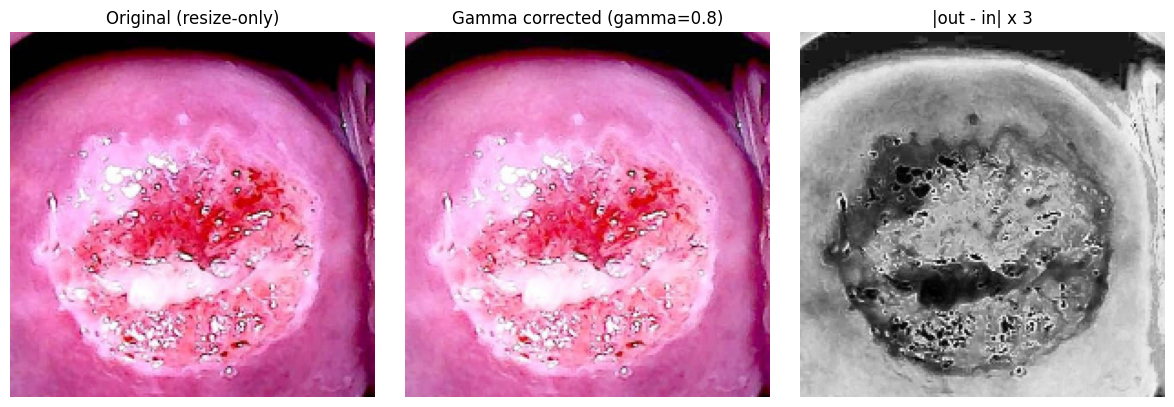

In [4]:
# ============================================================
# Cell 1.4 -- Gamma correction (the whole preprocessing pipeline)
# ============================================================
def gamma_correct(img_rgb, gamma=None):
    """Fixed-exponent gamma correction, applied per channel.

        I_out = 255 * (I_in / 255) ** gamma

    Rounded to nearest uint8 (single rounding step, so the transform is
    lossless in bit depth). Deterministic and stateless. gamma = 1.0 is an
    exact pass-through.
    """
    g = GAMMA if gamma is None else float(gamma)
    norm = np.asarray(img_rgb).astype(np.float64) / 255.0
    out = np.power(norm, g) * 255.0
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


# ---- Sanity checks ----
_chk = gamma_correct(X[0], gamma=1.0)
assert np.array_equal(_chk, X[0]), "gamma=1.0 must be an exact pass-through"
_g08 = gamma_correct(X[0])
assert _g08.shape == X[0].shape and _g08.dtype == np.uint8, \
    f"unexpected output: {_g08.shape} {_g08.dtype}"
assert np.array_equal(gamma_correct(X[0]), _g08), "gamma_correct must be deterministic"
print(f"gamma_correct ready | gamma={GAMMA} | out shape={_g08.shape} dtype={_g08.dtype}")
print(f"  mean |out-in| = "
      f"{np.abs(_g08.astype(int) - X[0].astype(int)).mean():.3f} grey levels")
print(f"  mean luma: in = {cv2.cvtColor(X[0], cv2.COLOR_RGB2GRAY).mean():.1f}  "
      f"out = {cv2.cvtColor(_g08, cv2.COLOR_RGB2GRAY).mean():.1f}")

# ---- Before/after for the first image ----
_diff = np.abs(_g08.astype(np.int16) - X[0].astype(np.int16)).mean(axis=-1)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(X[0]); ax[0].set_title("Original (resize-only)"); ax[0].axis("off")
ax[1].imshow(_g08); ax[1].set_title(f"Gamma corrected (gamma={GAMMA})"); ax[1].axis("off")
ax[2].imshow(np.clip(_diff * 3, 0, 255).astype(np.uint8), cmap="gray")
ax[2].set_title("|out - in| x 3"); ax[2].axis("off")
plt.tight_layout(); plt.show()

# Part B — Validation: 11 metrics, Gamma Correction vs original

Single-patient dataset. The frames are NOT independent (dHash clusters of
near-duplicate frames). Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Gamma Correction, fixed γ = 0.8, applied to the whole frame
after resize. **Reference row:** Identity (ideal values, not ranked).

**Metrics: 11 metrics in 5 groups.** All computed inside the FOV mask only,
per image, against the ORIGINAL image:

| #  | Metric                     | Group     | Better      |
|----|----------------------------|-----------|-------------|
| m1 | PSNR (dB)                  | fidelity  | up          |
| m2 | SSIM                       | fidelity  | up          |
| m3 | ΔE76 (CIE76)               | colour    | down        |
| m4 | a* correlation             | colour    | up          |
| m5 | \|a*\| shift               | colour    | down        |
| m6 | Vessel Dice                | structure | up          |
| m7 | Edge IoU                   | structure | up          |
| m8 | Sharpness ratio (out/in)   | quality   | neutral     |
| m9 | Noise ratio (out/in)       | quality   | down        |
| m10| Saturation ratio (out/in)  | quality   | neutral     |
| m11| Luma bits (effective)      | cost      | informational |

**Luma bits** is the Shannon entropy of the output luma histogram inside the
FOV (256 bins): the average number of bits/px the 8-bit luma actually uses.
Gamma correction does not quantize or drop bit depth, so this is an
informational statistic of the tone-mapped histogram, not a compression cost.

**Self-reference GT:** no clinician masks matched in the original run (0/128),
so the Vessel Dice and Edge IoU references are built from the ORIGINAL image
itself: the reference vessel map (top 10% Frangi pixels) and reference edge
map (Canny 50/150) come from the original, and the processed map from the
gamma-corrected image.

Output: per-image CSVs, a cluster-weighted main table with 95% bootstrap CIs
(T1), paired CIs vs Identity (T2), caveats (T3) and before/after figures.

In [5]:
# ============================================================
# Cell 2.1 -- Freeze inputs: FOV masks, image ids, dHash cluster ids.
#
# The QI-SABP cache_hash freeze is removed together with Part A: there is
# no frozen preprocessing left to protect. The FOV mask and the dHash
# clustering are technique-agnostic validation infrastructure and are kept
# exactly as they were.
# ============================================================
def _dhash(gray):
    """dHash (difference hash) -- 64-bit perceptual fingerprint."""
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()


def _compute_fov(img_rgb, thr=15):
    """FOV mask: largest bright connected region, holes filled, convex-hull
    notch fill + 11 px morphological close. Same definition the QI-SABP
    notebook used for validation, kept technique-agnostic."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill: fills notches at the frame edges (black triangles,
    # zigzag teeth) without extending the FOV past the bright region.
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1 + 1, x0:x1 + 1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                     cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov


images = X                     # (N, 200, 200, 3) uint8 RGB, resize-only
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov(images[i]) for i in range(n_images)])

# dHash clustering: greedy grouping of near-duplicate frames (<= 4 bit
# flips). Same as the original validator.
hs = [_dhash(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                         for uc in np.unique(cluster_ids)], dtype=int)

print(f"n_images = {n_images} | n_clusters (dHash) = {n_clusters}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")
print(f"  FOV coverage (mean over images): {fov.reshape(n_images, -1).mean(1).mean() * 100:.1f}% of frame")

n_images = 128 | n_clusters (dHash) = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.
  FOV coverage (mean over images): 95.8% of frame


In [6]:
# ============================================================
# Cell 2.2 -- Metric helpers + validator (11 metrics, FOV only).
# ============================================================
def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1).

    Self-reference: the map is computed on whatever image is passed in,
    so the REFERENCE map comes from the ORIGINAL image and the comparison
    map from the processed image."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    if _FRANGI_OK:
        try:
            v = _frangi_fn(gray, black_ridges=False)
            v = v / (v.max() + 1e-8)
            return v.astype(np.float32)
        except Exception:
            pass
    # Fallback: Sobel-based ridge detection
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    v = np.hypot(gx, gy)
    v = v / (v.max() + 1e-8)
    return v.astype(np.float32)


def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes Dice = 2*|A and B| / (|A| + |B|).
    This has more resolution than a pixel-wise correlation (which is
    0.997-0.999 for every variant)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom


def _edge_map(img_rgb):
    """Canny edge binary map (fixed thresholds 50 / 150)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)


def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])


def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)


def _specular_mask(img_rgb):
    """Specular/glare mask (same as the original validator)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)


def _luma_bits_effective(processed, fov_mask, bins=256):
    """m11 -- Luma bits: Shannon entropy (bits/px) of the luma histogram
    inside the FOV. The average number of bits/px the 8-bit luma actually
    uses. Gamma correction does not quantize, so this is an informational
    statistic of the tone-mapped histogram, not a compression cost."""
    gray = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    vals = gray[np.asarray(fov_mask, dtype=bool)].ravel()
    if vals.size == 0:
        return float('nan')
    hist = np.bincount(vals, minlength=bins).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def gamma_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                        up
      m2  SSIM                             up
      m3  DeltaE76 (CIE76)                 down
      m4  a* correlation                   up
      m5  |a* shift|                       down
      m6  Vessel Dice                      up
      m7  Edge IoU                         up
      m8  Sharpness ratio (out/in)         neutral
      m9  Noise ratio (out/in)             down
      m10 Saturation ratio (out/in)        neutral
      m11 Luma bits (effective, entropy)   informational
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: DeltaE76 (CIE76)
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m3 = float(_deltaE_fn(lab_o, lab_p)[f].mean())
    # m4: a* correlation
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    m7 = _edge_iou(_edge_map(original), _edge_map(processed), f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of the high-pass, evaluated
    # only in smooth regions (gradient below the 30th percentile).
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures NEW
    # saturation introduced by the technique. A ratio > 1 means the technique
    # adds saturated pixels; ratio <= 1 is good.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (effective, entropy of the processed luma inside FOV)
    m11 = _luma_bits_effective(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)


# Metric metadata (key, display name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",        "fidelity",  "up"),
    ("m2",  "SSIM",             "fidelity",  "up"),
    ("m3",  "DeltaE76 (CIE76)", "colour",    "down"),
    ("m4",  "a* corr",          "colour",    "up"),
    ("m5",  "|a* shift|",       "colour",    "down"),
    ("m6",  "Vessel Dice",      "structure", "up"),
    ("m7",  "Edge IoU",         "structure", "up"),
    ("m8",  "Sharpness ratio",  "quality",   "neutral"),
    ("m9",  "Noise ratio",      "quality",   "down"),
    ("m10", "Saturation ratio", "quality",   "neutral"),
    ("m11", "Luma bits",        "cost",      "info"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("gamma_validator ready: 11 metrics (m1..m11).")

gamma_validator ready: 11 metrics (m1..m11).


In [7]:
# ============================================================
# Cell 2.3 -- Compute 11 metrics per image (Gamma + Identity).
#             Write per-image CSVs.
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "Gamma Correction (g=0.8)"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB

# ---- Gamma Correction rows ----
rows = []
t_start = time.perf_counter()
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    proc = gamma_correct(orig)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    m = gamma_validator(orig, proc, fov_i)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")
_elapsed = (time.perf_counter() - t_start) * 1000.0
df_gamma = pd.DataFrame(rows)
df_gamma.to_csv("results_Gamma_Correction.csv", index=False)
print(f"Wrote results_Gamma_Correction.csv ({len(df_gamma)} rows) "
      f"| batch time = {_elapsed:.0f} ms")

# ---- Identity reference rows ----
for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
rows_id = []
for i in range(n_images):
    m = gamma_validator(images[i], images[i], fov[i])
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

print(f"  Gamma    mean: PSNR={df_gamma['m1'].mean():.2f} dB  "
      f"SSIM={df_gamma['m2'].mean():.3f}  DeltaE76={df_gamma['m3'].mean():.2f}  "
      f"luma bits={df_gamma['m11'].mean():.3f}")
print(f"  Identity mean: PSNR={df_id['m1'].mean():.2f} dB  "
      f"SSIM={df_id['m2'].mean():.3f}  DeltaE76={df_id['m3'].mean():.2f}  "
      f"luma bits={df_id['m11'].mean():.3f}")

  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_Gamma_Correction.csv (128 rows) | batch time = 40609 ms
Wrote results_Identity.csv (128 rows)
  Gamma    mean: PSNR=25.50 dB  SSIM=0.979  DeltaE76=7.39  luma bits=7.465
  Identity mean: PSNR=148.13 dB  SSIM=1.000  DeltaE76=0.00  luma bits=7.578


In [8]:
# ============================================================
# Cell 2.4 -- Merge the two technique CSVs. Assert each technique has
#             n_images rows and the same cluster ids. Assert no NaNs.
# Uses a FIXED list of CSV names (not glob) to prevent stale files
# from earlier runs leaking into the tables.
# ============================================================
_csv_names = [
    "results_Gamma_Correction.csv",
    "results_Identity.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any metric column.
_nan_cols = {}
for col in METRIC_KEYS:
    n_nan = int(merged[col].isna().sum())
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, (
    f"NaN values found: {_nan_cols}. Check the FOV masks and the "
    f"vessel/edge reference maps."
)
print("No NaN values in any metric column.")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")

Reading 2 CSV files (fixed list, not glob)
  results_Gamma_Correction.csv: 128 rows, technique = Gamma Correction (g=0.8)
  results_Identity.csv: 128 rows, technique = Identity
Merged: 256 rows, 2 techniques
No NaN values in any metric column.
Techniques: ['Gamma Correction (g=0.8)', 'Identity']


In [9]:
# ============================================================
# Cell 2.5 -- Aggregation: average within each cluster first, then
#             across clusters. 95% CI from a cluster bootstrap (2000
#             resamples, fixed seed).
#             Label: "within-patient, dHash clusters, not a population CI".
# ============================================================
def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())


def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=N_BOOT, seed=BOOTSTRAP_SEED):
    """Bootstrap CI over clusters. Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))


# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print("  WITHIN-PATIENT, dHash clusters, NOT a population CI.")

Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, dHash clusters, NOT a population CI.


In [10]:
# ============================================================
# Cell 2.6 -- Statistics: Gamma Correction vs Identity, per key metric.
#             Uses paired difference per cluster + bootstrap CI. Reports
#             "CI excludes 0: yes/no". Descriptive, no significance claim.
#             PSNR / SSIM are skipped vs Identity (meaningless there).
# ============================================================
def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=N_BOOT,
                            seed=BOOTSTRAP_SEED):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes


# Key metrics for the paired comparison (skip PSNR/SSIM vs Identity --
# they are meaningless: ~148 dB / SSIM=1 by construction).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]

stat_rows = []
gamma_df = merged[merged["technique"] == TECHNIQUE]
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(gamma_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk],
        "comparison": "Gamma Correction vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. Gamma Correction vs Identity, key metrics only.")
print("  Descriptive, no significance claim. dHash clusters, within-patient.")

Statistics done. Gamma Correction vs Identity, key metrics only.
  Descriptive, no significance claim. dHash clusters, within-patient.


In [11]:
# ============================================================
# Cell 2.7 -- Print tables T1 (main), T2 (paired CIs), T3 (caveats).
# ============================================================
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

# ---- T1 MAIN ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, dHash clusters, NOT a population CI)")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 110)
arrow_map = {"up": "^", "down": "v", "neutral": "o", "info": "i"}
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T2 PAIRED CIs ----
print()
print("=" * 110)
print("T2 PAIRED CIs  (Gamma Correction vs Identity; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 110)
_meaningful_thresh = {"DeltaE76 (CIE76)": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                      "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df.copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T3 CAVEATS ----
print()
print("=" * 110)
print("T3 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    "Single patient; frames are NOT independent (dHash clusters of near-duplicate frames).",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks matched (0/128 in the original run); vessel and edge references are "
    "SELF-references: the reference map comes from the ORIGINAL image, the comparison map "
    "from the gamma-corrected image.",
    "PSNR / SSIM / DeltaE76 measure the DEVIATION from the original. For a tone transform "
    "such as gamma correction the deviation is by design; read them together with the "
    "structure metrics (Vessel Dice, Edge IoU).",
    f"Gamma is FIXED at {GAMMA} for every image: no per-image adaptation, no tuning on this "
    "patient. Set GAMMA=1.0 in the config cell to reproduce the Identity row exactly.",
    "Luma bits (m11) is the Shannon entropy of the output luma histogram inside the FOV "
    "(256 bins): the average bits/px the 8-bit luma actually uses. Gamma does not quantize; "
    "this is informational, not a compression cost.",
    "DeltaE76 (not CIEDE2000).",
    "Sharpness ratio (m8) and Saturation ratio (m10) are neutral, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed. "
    "Gamma correction does not denoise, so a high IoU is expected.",
    "Vessel Dice (m6): Dice of the top 10% Frangi pixels inside the FOV, 2*|A and B|/(|A|+|B|).",
    "Identity is a reference row only. Its PSNR (~148 dB) comes from the 1e-10 MSE floor in "
    "the PSNR formula (exact 0 MSE is floored before the log).",
    "95% CI is WITHIN-PATIENT (cluster bootstrap), NOT a population CI.",
]
for c in caveats:
    print(f"  - {c}")

T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, dHash clusters, NOT a population CI)
  Identity is a reference row (ideal values, not ranked).
                                       PSNR (dB) (^)              SSIM (^)  DeltaE76 (CIE76) (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)         Luma bits (i)
technique                                                                                                                                                                                                                                                                       
Gamma Correction (g=0.8)     25.563 [25.362, 25.815]  0.980 [0.977, 0.982]  7.430 [7.381, 7.473]  0.975 [0.969, 0.980]  4.292 [4.003, 4.633]  0.946 [0.944, 0.949]  0.842 [0.832, 0.851]  0.876 [0.872, 0.880]  0.917 [0.899, 0.935]  1.314 [1.267, 1.373]  7.451 [7.342, 7.534]
Identity                  14

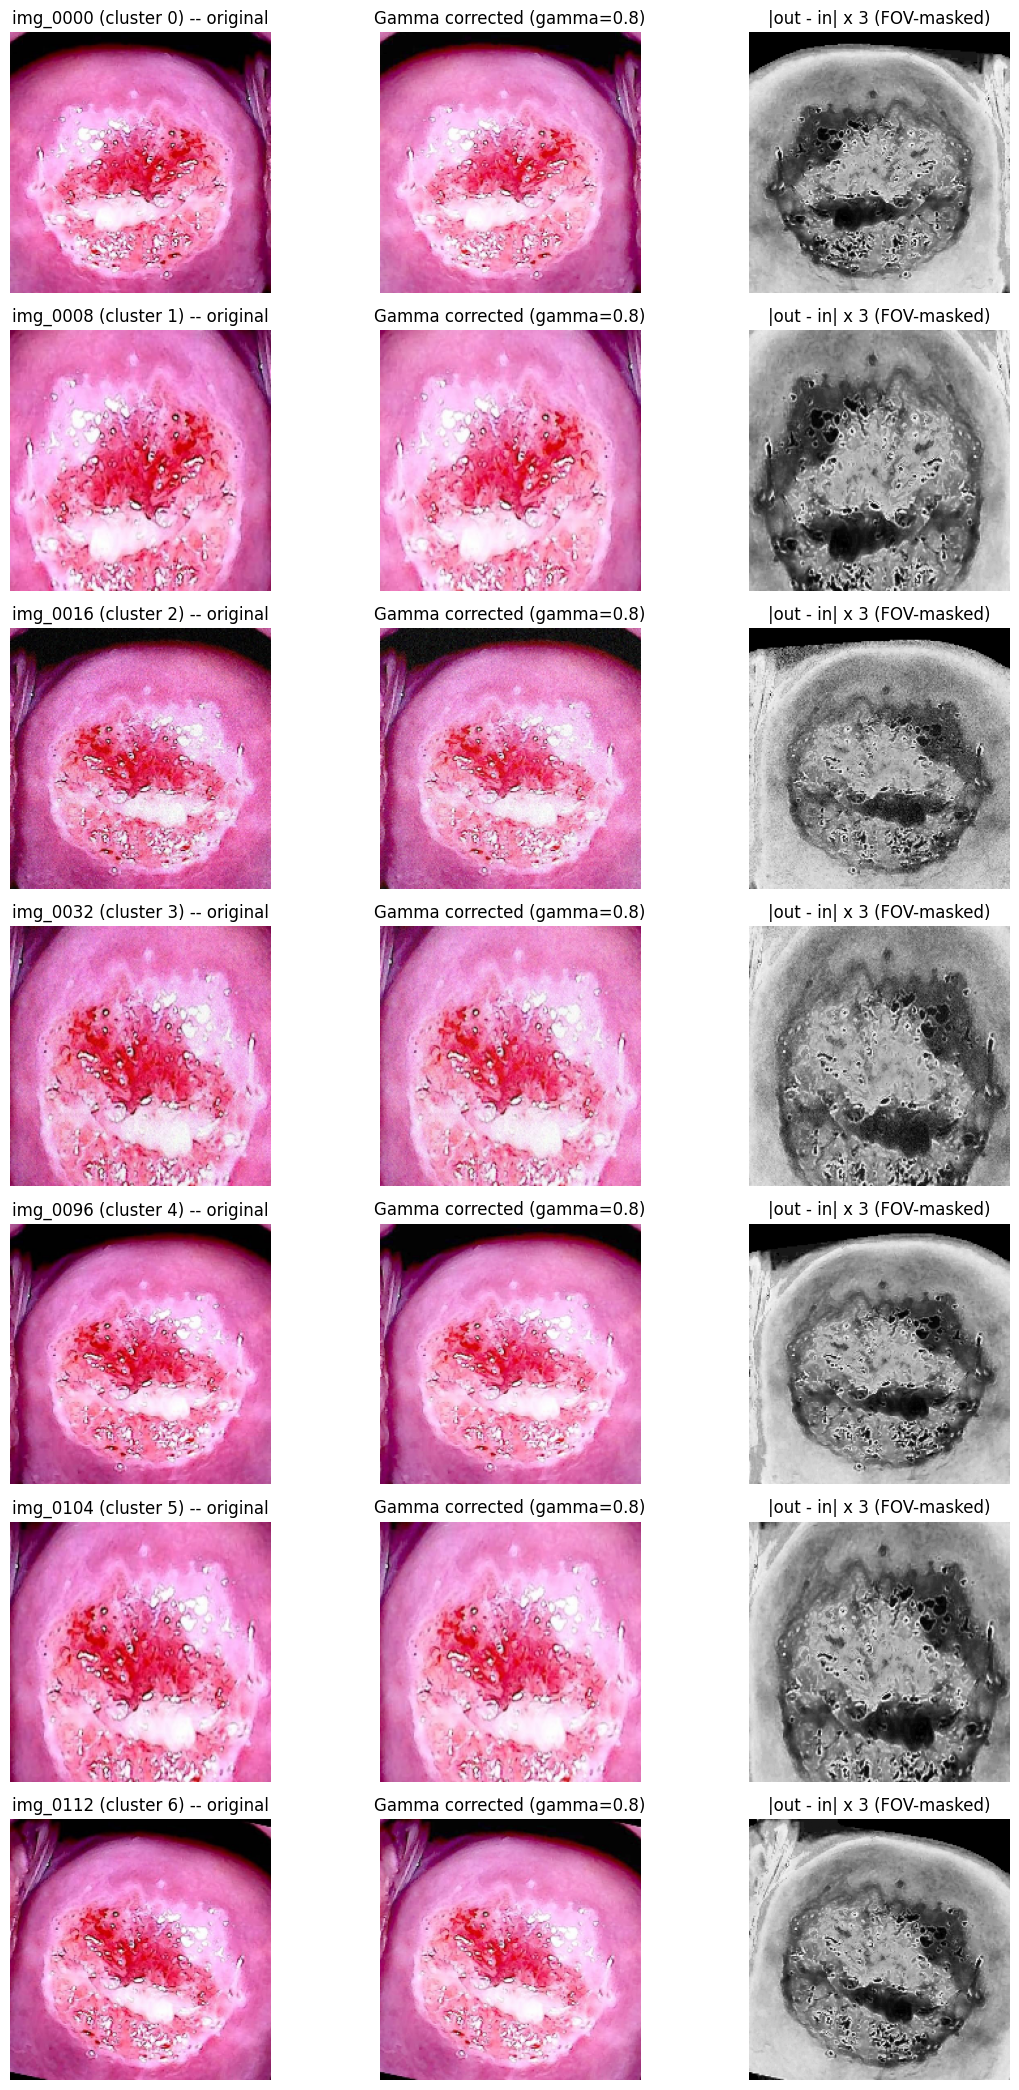

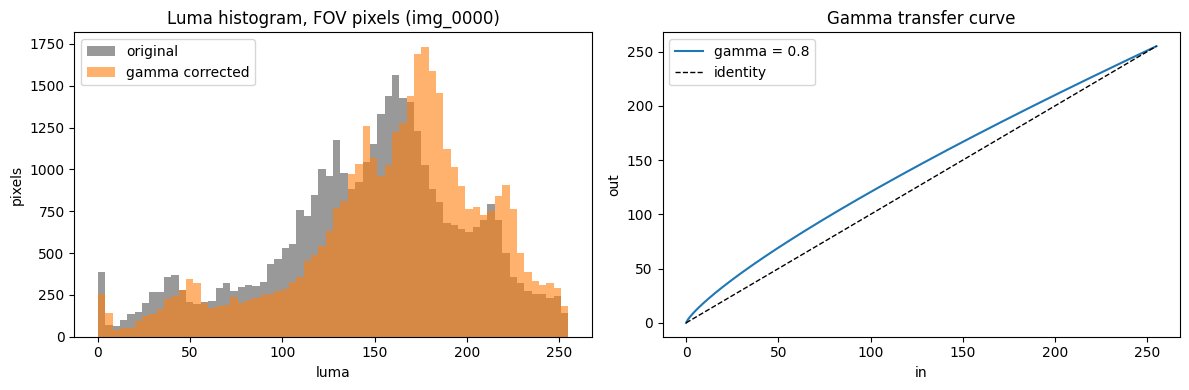

In [12]:
# ============================================================
# Cell 2.8 -- Before/after figures (one frame per dHash cluster)
#             + luma histograms + the gamma transfer curve.
# ============================================================
n_show = len(cluster_reps)
fig, axes = plt.subplots(n_show, 3, figsize=(12, 3 * n_show), squeeze=False)
for r, i in enumerate(cluster_reps):
    orig = images[i]
    proc = processed_cache[(TECHNIQUE, i)]
    diff = np.abs(proc.astype(np.float32) - orig.astype(np.float32)).mean(axis=-1)
    diff[~fov[i]] = 0.0
    axes[r][0].imshow(orig)
    axes[r][0].set_title(f"{image_id[i]} (cluster {cluster_ids[i]}) -- original")
    axes[r][0].axis("off")
    axes[r][1].imshow(proc)
    axes[r][1].set_title(f"Gamma corrected (gamma={GAMMA})")
    axes[r][1].axis("off")
    axes[r][2].imshow(np.clip(diff * 3, 0, 255), cmap="gray")
    axes[r][2].set_title("|out - in| x 3 (FOV-masked)")
    axes[r][2].axis("off")
plt.tight_layout(); plt.show()

# ---- Luma histogram: original vs gamma-corrected (first cluster rep) ----
i0 = int(cluster_reps[0])
g_o = cv2.cvtColor(images[i0], cv2.COLOR_RGB2GRAY)[fov[i0]]
g_p = cv2.cvtColor(processed_cache[(TECHNIQUE, i0)], cv2.COLOR_RGB2GRAY)[fov[i0]]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(g_o.ravel(), bins=64, range=(0, 255), color="0.5", alpha=0.8, label="original")
ax[0].hist(g_p.ravel(), bins=64, range=(0, 255), color="tab:orange", alpha=0.6,
           label="gamma corrected")
ax[0].set_title(f"Luma histogram, FOV pixels ({image_id[i0]})")
ax[0].set_xlabel("luma"); ax[0].set_ylabel("pixels"); ax[0].legend()
xs = np.arange(256, dtype=np.float64) / 255.0
ax[1].plot(np.arange(256), np.power(xs, GAMMA) * 255.0, label=f"gamma = {GAMMA}")
ax[1].plot([0, 255], [0, 255], "k--", linewidth=1, label="identity")
ax[1].set_title("Gamma transfer curve")
ax[1].set_xlabel("in"); ax[1].set_ylabel("out"); ax[1].legend()
plt.tight_layout(); plt.show()

## How to read the results

* **Fidelity (m1 PSNR, m2 SSIM).** These measure the deviation of the
  gamma-corrected image from the original. For a tone transform the deviation
  is by design: gamma = 0.8 deliberately moves the mid-tones, so a moderate
  PSNR / SSIM drop is expected and is not an error signal. Read them together
  with the structure metrics.
* **Colour (m3 ΔE76, m4 a* correlation, m5 \|a*\| shift).** Gamma raises the
  lightness of dark tissue, which also shifts the a* and b* coordinates a
  little in CIELAB. A high a* correlation (hue ordering preserved) with a
  small |a*| shift is the expected, healthy signature of a pure tone
  transform.
* **Structure (m6 Vessel Dice, m7 Edge IoU).** Both use self-references built
  from the original image. Gamma is monotonic and does not filter, so vessels
  and edges should survive: expect high Dice and high IoU. A collapse here
  would indicate the exponent is too aggressive for this data.
* **Quality (m8 Sharpness ratio, m9 Noise ratio, m10 Saturation ratio).**
  All three are ratios (out/in). Gamma slightly stretches the upper tones, so
  the sharpness ratio may drift a little above 1; noise ratio should stay
  close to 1 because gamma is smooth and adds no noise; the saturation ratio
  tracks new specular pixels (≤ 1 is good).
* **Cost (m11 Luma bits).** Informational only: the entropy of the output
  luma histogram inside the FOV. Gamma re-maps the histogram, so the value
  can move slightly in either direction; it is not a compression number.
* The 95% CIs are **within-patient** (cluster bootstrap over dHash clusters).
  They describe the variability of THESE frames only — they are not a
  population claim.